# Development of the learned weight matrix

**Julian Hoyer's experiment.** Original and COM-sorted weight matrices during
the same $\lambda=1$, noise-free minibatch run as `predictive_rule.ipynb`.
The layouts follow Clark et al.'s Figure 2a,b: rows are receiving neurons,
columns are sending neurons, and a diverging map distinguishes negative and
positive weights. All outputs below are embedded; no execution is needed to
view the figures.

The learning sequence is: present a batch, obtain the somatic activity, compute
the recurrent prediction, apply the update, and repeat. For $\lambda=1$,
$x_i(\theta)=h_i(\theta)$ at every step. Thus changing $J$ changes the prediction
$p_i$, **not the clamped tuning curves**. Changing the presented angle changes
the state; it does not change the neuron's full tuning curve across angles.

### COM convention

As in Figure 2b and `ring.data_driven.sort_weight_matrix`, sort using the circular
COM of the full **firing-rate tuning curve**, not of a single instantaneous state
or of a random minibatch:

\[
\mu_i^{(n)}=\arg\!\left[\sum_\theta
\phi(x_i^{(n)}(\theta))e^{i\theta}\right]\pmod{2\pi}.
\]

COM and the sorting permutation are recomputed at every displayed checkpoint.
They remain unchanged here because $x_i^{(n)}(\theta)=h_i(\theta)$ for
$\lambda=1$. A changing COM would require a different definition, such as
autonomous response-derived tuning, or a different training condition. We do
not substitute such a definition for the paper's sorting convention.

Steps 1–10 are reconstructed by replaying only ten updates with the original
angle RNG. Step 10 must match the saved checkpoint to float64 precision before
figures are made. Later checkpoints are loaded read-only. This is the actual
minibatch trajectory, rather than the deterministic full-batch SVD trajectory.
Nothing in `ring/`, `data/` or either previous output directory is modified.

In [1]:
import base64
import json
import os
import sys
from io import BytesIO
from pathlib import Path

sys.dont_write_bytecode = True
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import numpy as np
import pandas as pd
import torch
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.colors import Normalize
from IPython.display import Image, display
from PIL import Image as PILImage

here = Path.cwd().resolve()
parents = [here, *here.parents]
candidates = parents + [p / '.worktrees/local-learning' for p in parents]
ROOT = next(p for p in candidates if
            (p / 'notebooks/predictive_rule_outputs/full/model.npz').is_file())
sys.path.insert(0, str(ROOT))
from ring import data_driven, fn, style

SOURCE = ROOT / 'notebooks/predictive_rule_outputs/full'
OUT = ROOT / 'notebooks/weight_development_outputs'
OUT.mkdir(exist_ok=True)
config = json.loads((SOURCE / 'config.json').read_text())
with np.load(SOURCE / 'model.npz', allow_pickle=False) as model:
    H, Phi, J_paper = model['H'].copy(), model['Phi'].copy(), model['J_paper'].copy()
N, N_theta = config['N'], config['N_theta']
BATCH, ETA0, BETA, SEED = config['batch'], config['eta0'], config['beta'], config['seed']
DEVICE, DTYPE = torch.device(config['device']), torch.float64
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

def nonlin(x):
    return fn.nonlin_idealized(x, BETA)

def show_figure(fig, filename, dpi=145):
    path = OUT / filename
    fig.savefig(path, dpi=dpi)
    with PILImage.open(path) as image:
        preview = image.convert('RGB')
        preview.thumbnail((1100, 1100))
        preview = preview.quantize(colors=256)
        buffer = BytesIO()
        preview.save(buffer, format='PNG', optimize=True)
    display(Image(data=buffer.getvalue()))

print(f'lambda = 1; update noise = 0; N = {N}; batch = {BATCH}; eta0 = {ETA0}.')
print('Generated figures and tables:', OUT)

lambda = 1; update noise = 0; N = 1000; batch = 50; eta0 = 0.5.
Generated figures and tables: /Users/julianhoyer/Documents/symmetries-continuous-attractors/.worktrees/local-learning/notebooks/weight_development_outputs


## Recover the first ten steps and load later weights

For each independent batch of 50 angle indices, the original run applies
\[
\Delta J=\frac{\eta_0}{NB}(H_B^T-J\phi(H_B)^T)\phi(H_B),
\qquad J\leftarrow J+\Delta J,\quad J_{ii}\leftarrow0.
\]
The implementation below retains the original operation order and random seed.
There is no rerun of the 30,000-step training experiment.

In [2]:
H_t = torch.as_tensor(H, dtype=DTYPE, device=DEVICE)
J = torch.zeros((N, N), dtype=DTYPE, device=DEVICE)
angle_rng = torch.Generator(device=DEVICE).manual_seed(SEED + 2)
snapshots = {0: J.cpu().numpy().copy()}
with torch.no_grad():
    for step in range(1, 11):
        indices = torch.randint(N_theta, (BATCH,), device=DEVICE, generator=angle_rng)
        x = H_t[indices].T
        rates = nonlin(x)
        p = J @ rates
        update = (ETA0 / N) * ((x - p) @ rates.T) / x.shape[1]
        update.fill_diagonal_(0)
        J.add_(update)
        J.fill_diagonal_(0)
        snapshots[step] = J.cpu().numpy().copy()

saved_path = SOURCE / 'lam_1_noise_0/step_00010/weights.npz'
with np.load(saved_path, allow_pickle=False) as data:
    original_step10 = data['J'].copy()
relative_error = np.linalg.norm(snapshots[10] - original_step10) / np.linalg.norm(original_step10)
np.testing.assert_allclose(snapshots[10], original_step10, rtol=1e-12, atol=1e-14)
assert relative_error < 1e-12
print(f'PASS: replayed step 10 matches the original saved weights; relative error = {relative_error:.3g}.')

for path in sorted((SOURCE / 'lam_1_noise_0').glob('step_*/weights.npz')):
    step = int(path.parent.name.split('_')[1])
    if step <= 10:
        continue
    with np.load(path, allow_pickle=False) as data:
        snapshots[step] = data['J'].copy()
STEPS = sorted(snapshots)
assert all(np.isfinite(matrix).all() and np.all(matrix.diagonal() == 0)
           for matrix in snapshots.values())
print('Displayed training steps:', STEPS)

PASS: replayed step 10 matches the original saved weights; relative error = 0.


Displayed training steps: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 30, 100, 300, 1000, 3000, 10000, 30000]


## Recalculate COM and fix the color scale

The same permutation is applied to rows and columns. To match the original
figure's implementation, angular COMs are converted to angular-bin indices before
sorting. Both signs use one color scale across every checkpoint and the paper
reference. The limit is the larger 99th percentile of absolute weights in the
final learned matrix and paper matrix; rarer extremes saturate. No matrix is
normalized separately, so the growth of weight amplitude remains visible.

In [3]:
orders, coms = {}, {}
rows, com_rows = [], []
reference_com = data_driven.circular_com(Phi.T)
COLOR_LIMIT = max(float(np.quantile(np.abs(snapshots[STEPS[-1]]), .99)),
                  float(np.quantile(np.abs(J_paper), .99)))
NORM = Normalize(vmin=-COLOR_LIMIT, vmax=COLOR_LIMIT)
CMAP = style.DIVERGING_CMAP
paper_norm = np.linalg.norm(J_paper)
for step in STEPS:
    # Full theta-conditioned somatic responses at this checkpoint. They remain
    # H under lambda=1, even though the recurrent prediction changes with J.
    x_curves = H.copy()
    firing_curves = nonlin(x_curves)
    np.testing.assert_allclose(firing_curves, Phi, rtol=0, atol=0)
    coms[step] = data_driven.circular_com(firing_curves.T)
    _, orders[step] = data_driven.sort_weight_matrix(snapshots[step], firing_curves)
    change = np.rad2deg(np.angle(np.exp(1j * (coms[step] - reference_com))))
    matrix = snapshots[step]
    rows.append(dict(step=step, weight_rms=float(np.sqrt(np.mean(matrix**2))),
                     weight_norm=float(np.linalg.norm(matrix)),
                     relative_distance_from_paper=float(np.linalg.norm(matrix-J_paper)/paper_norm),
                     fraction_color_saturated=float(np.mean(np.abs(matrix) > COLOR_LIMIT)),
                     maximum_com_change_deg=float(np.max(np.abs(change)))))
    inverse_order = np.argsort(orders[step])
    com_rows.extend(dict(step=step, neuron=i+1, com_deg=float(np.rad2deg(coms[step][i])),
                         sorted_rank=int(inverse_order[i])+1) for i in range(N))

summary = pd.DataFrame(rows)
summary.to_csv(OUT / 'checkpoint_summary.csv', index=False)
pd.DataFrame(com_rows).to_csv(OUT / 'com_at_each_checkpoint.csv', index=False)
assert summary.maximum_com_change_deg.max() < 1e-10
assert all(np.array_equal(orders[step], orders[0]) for step in STEPS)
paper_sorted, paper_order = data_driven.sort_weight_matrix(J_paper, Phi)
assert np.array_equal(paper_order, orders[0])
print(f'COM recomputed at {len(STEPS)} checkpoints; maximum change = {summary.maximum_com_change_deg.max():.3g} degrees.')
print(f'Common color limits: {-COLOR_LIMIT:.6g} to {COLOR_LIMIT:.6g}.')
display(summary)

COM recomputed at 18 checkpoints; maximum change = 0 degrees.
Common color limits: -0.00854639 to 0.00854639.


,step,weight_rms,weight_norm,relative_distance_from_paper,fraction_color_saturated,maximum_com_change_deg
0,0,0.000000,0.000000,1.000000,0.000000,0.0
1,1,0.000323,0.323033,0.953947,0.000000,0.0
2,2,0.000495,0.495447,0.918742,0.000000,0.0
3,3,0.000609,0.609154,0.887341,0.000000,0.0
4,4,0.000704,0.703857,0.858848,0.000000,0.0
5,5,0.000798,0.797546,0.833418,0.000000,0.0
6,6,0.000878,0.877527,0.808441,0.000000,0.0
7,7,0.000956,0.956236,0.785511,0.000000,0.0
8,8,0.001034,1.033775,0.764895,0.000000,0.0
9,9,0.001110,1.110013,0.744720,0.000000,0.0


In [4]:
def matrix_at(step, sorted_by_com=False):
    if step == 'paper':
        return paper_sorted if sorted_by_com else J_paper
    matrix = snapshots[step]
    if sorted_by_com:
        order = orders[step]
        matrix = matrix[np.ix_(order, order)]
    return matrix

def draw_matrix(ax, matrix, title, sorted_by_com):
    image = ax.imshow(matrix, norm=NORM, cmap=CMAP, interpolation='nearest',
                      origin='upper', rasterized=True)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([0, N-1], ['1', str(N)])
    ax.set_yticks([0, N-1], ['1', str(N)])
    ax.tick_params(labelsize=7)
    ax.set_xlabel('Presynaptic COM rank' if sorted_by_com else 'Presynaptic neuron j', fontsize=8)
    ax.set_ylabel('Postsynaptic COM rank' if sorted_by_com else 'Postsynaptic neuron i', fontsize=8)
    ax.set_aspect('equal')
    return image

def grid_figure(steps, sorted_by_com, title, filename):
    columns = 4
    nrows = (len(steps) + columns - 1) // columns
    fig = Figure(figsize=(12, 3.05*nrows + .6), layout='constrained')
    axes = fig.subplots(nrows, columns, squeeze=False)
    for ax, step in zip(axes.flat, steps):
        label = 'Paper reference' if step == 'paper' else f'Step {step:,}'
        im = draw_matrix(ax, matrix_at(step, sorted_by_com), label, sorted_by_com)
    for ax in list(axes.flat)[len(steps):]:
        ax.set_visible(False)
    fig.colorbar(im, ax=list(axes.flat)[:len(steps)], shrink=.7, fraction=.025,
                 label='Jij (same scale at every step)', extend='both')
    fig.suptitle(title, fontsize=13)
    show_figure(fig, filename)

## First ten updates: original neuronal order

Step 0 shows the zero initialization; steps 1–10 show every update. The final
panel is the paper reference on the same input realization and color scale.

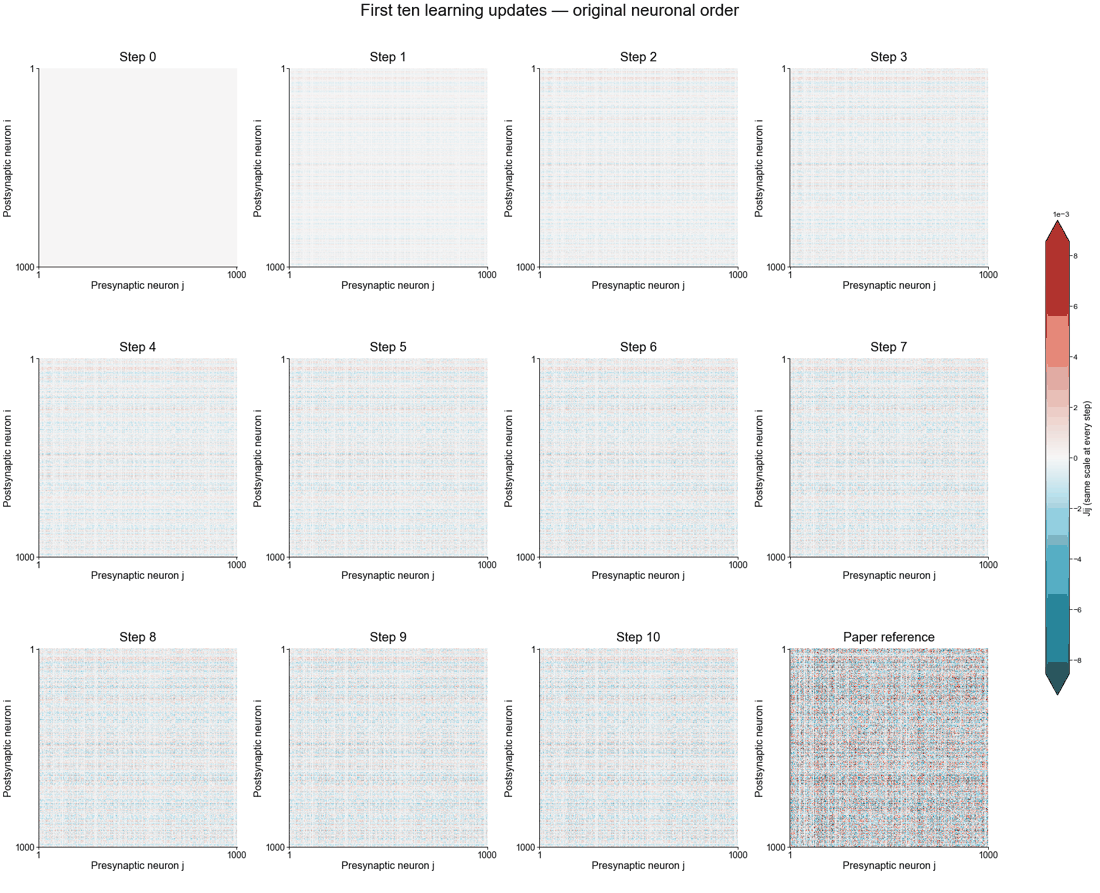

In [5]:
EARLY = list(range(11)) + ['paper']
grid_figure(EARLY, False, 'First ten learning updates — original neuronal order', 'first_10_original.png')

## First ten updates: COM-sorted order

COM is recalculated from the full clamped tuning curves at every displayed step.
The order remains identical; emerging changes in these panels are changes in J.

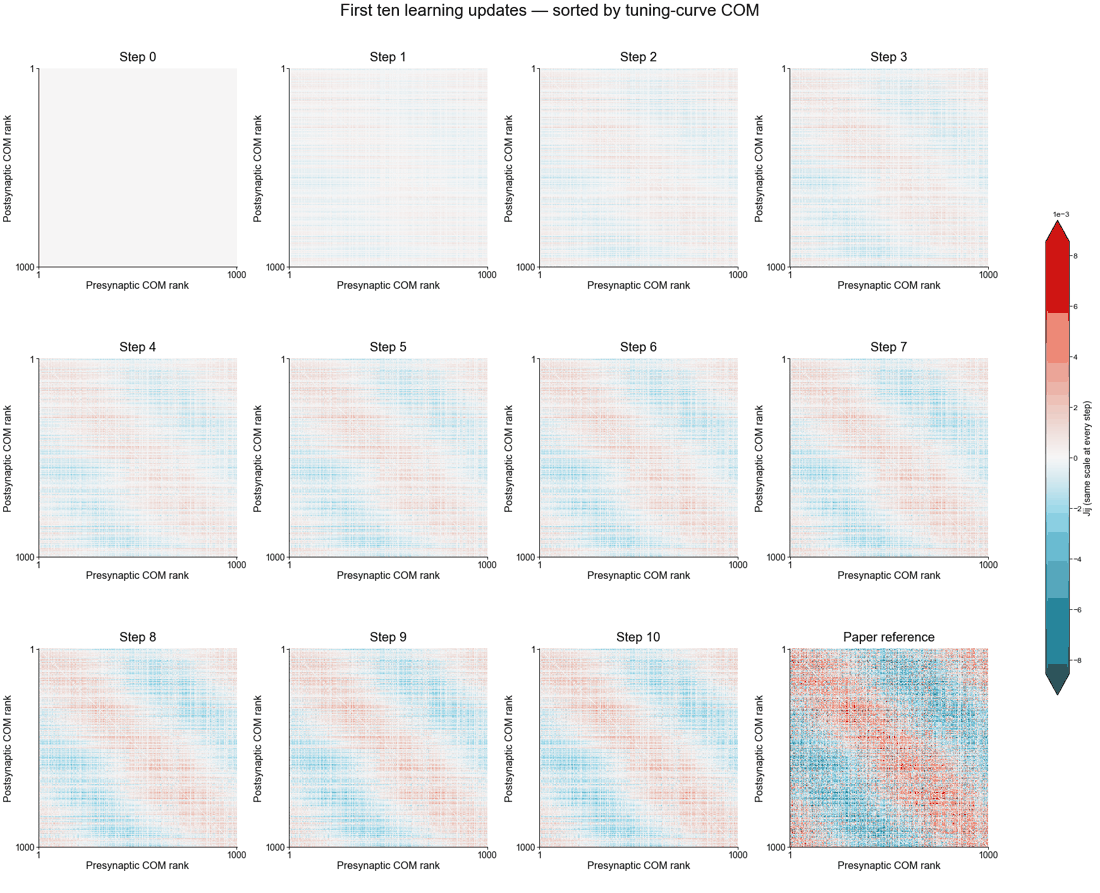

In [6]:
grid_figure(EARLY, True, 'First ten learning updates — sorted by tuning-curve COM', 'first_10_com_sorted.png')

## Later checkpoints: original neuronal order

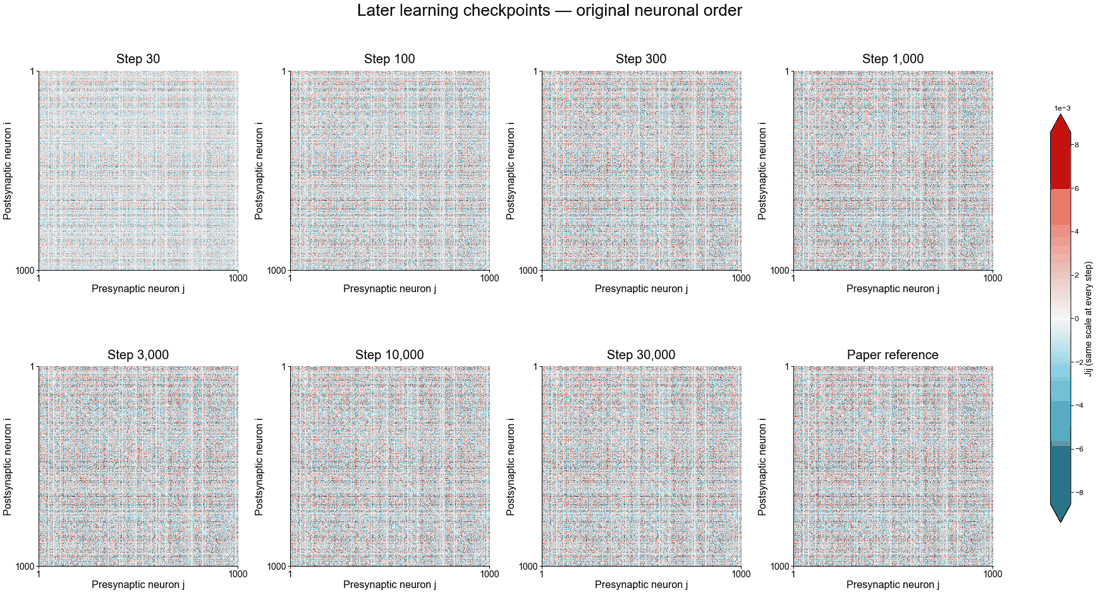

In [7]:
LATER = [step for step in STEPS if step > 10] + ['paper']
grid_figure(LATER, False, 'Later learning checkpoints — original neuronal order', 'later_original.png')

## Later checkpoints: COM-sorted order

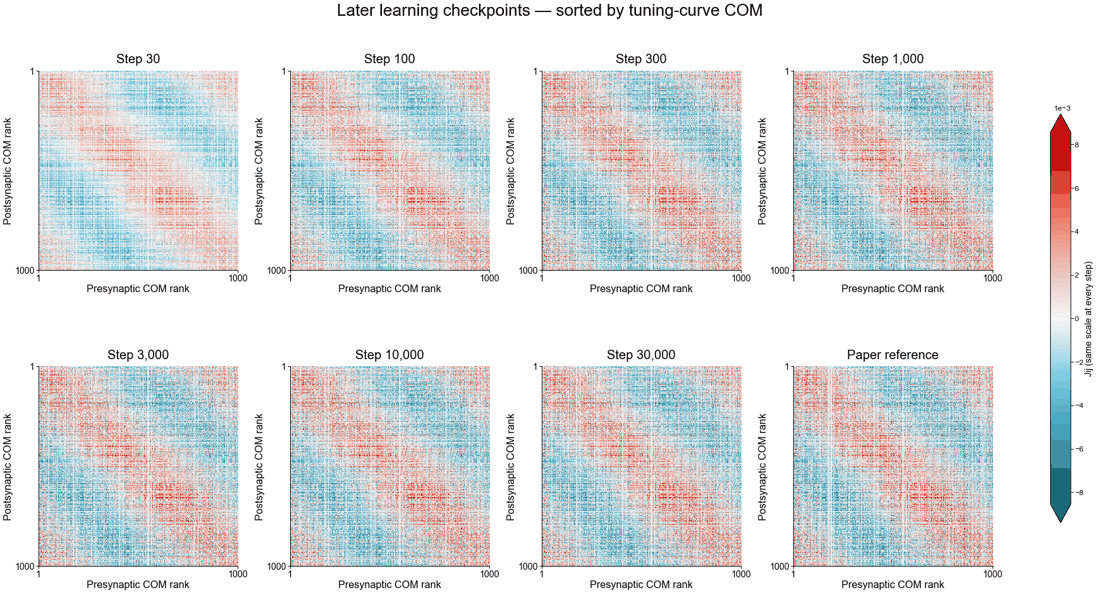

In [8]:
grid_figure(LATER, True, 'Later learning checkpoints — sorted by tuning-curve COM', 'later_com_sorted.png')

## Final learned matrix beside the paper reference

The columns correspond to Figure 2a,b: arbitrary order on the left and the same
matrix sorted by tuning-curve COM on the right. The learned matrix uses the final
saved minibatch checkpoint; the lower row is the analytical paper reference.

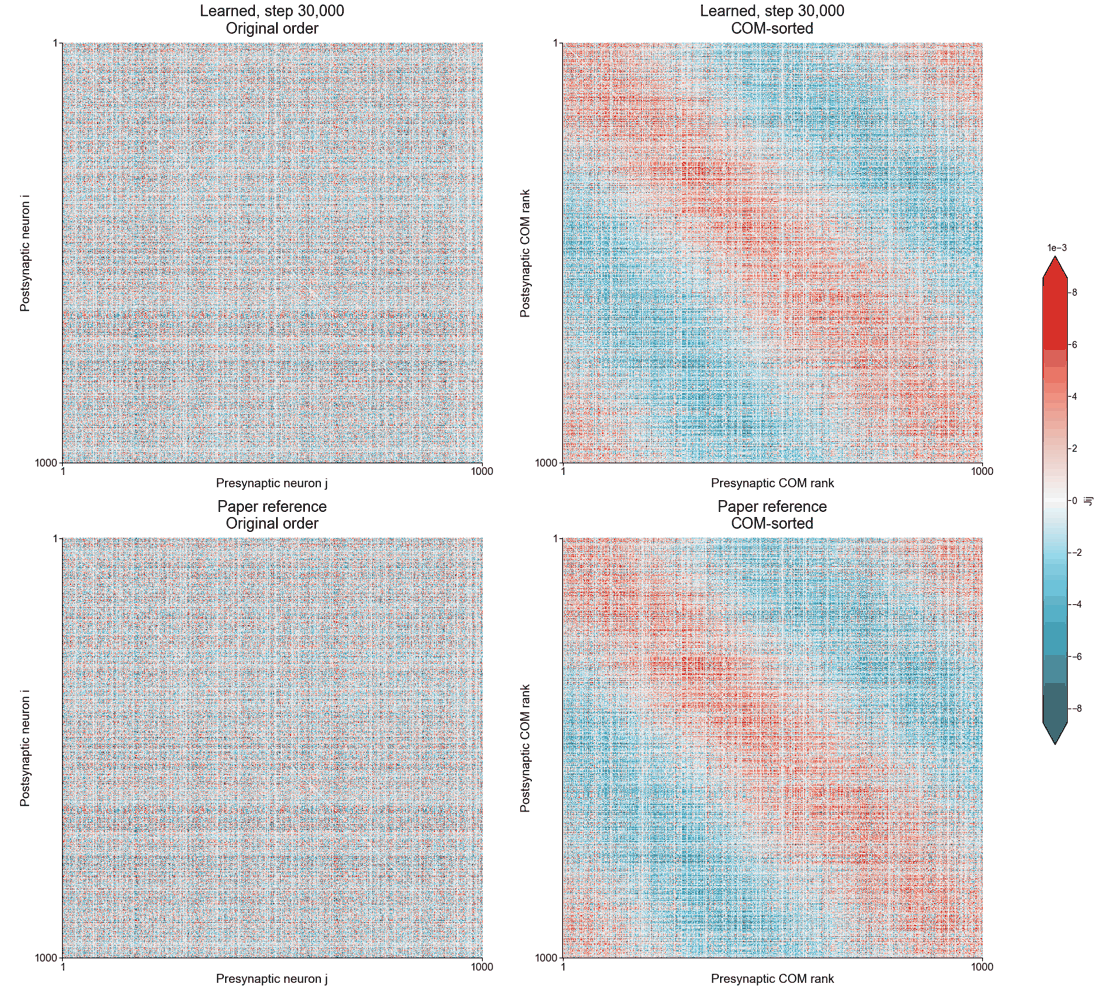

In [9]:
fig = Figure(figsize=(10, 9), layout='constrained')
axes = fig.subplots(2, 2)
for row, step in enumerate([STEPS[-1], 'paper']):
    name = f'Learned, step {step:,}' if step != 'paper' else 'Paper reference'
    for col, sorted_by_com in enumerate([False, True]):
        order_label = 'COM-sorted' if sorted_by_com else 'Original order'
        im = draw_matrix(axes[row, col], matrix_at(step, sorted_by_com),
                         f'{name}\n{order_label}', sorted_by_com)
fig.colorbar(im, ax=list(axes.flat), shrink=.7, fraction=.025, label='Jij', extend='both')
show_figure(fig, 'final_and_paper.png', dpi=170)

## Animated development

The left panel retains the original neuron order; the right uses COM sorting
recomputed at each checkpoint. Both use the same fixed color scale as the grids.
The animation advances through saved update numbers, not uniformly spaced
physical time. Inline figures and the animation use compact previews; the
full-resolution PNGs and GIF can be opened directly from the output folder.

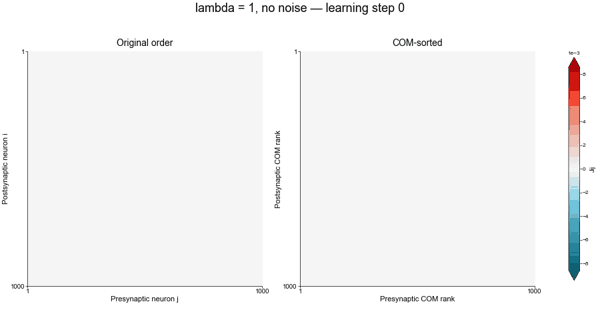

Animation: /Users/julianhoyer/Documents/symmetries-continuous-attractors/.worktrees/local-learning/notebooks/weight_development_outputs/weight_development.gif


In [10]:
fig = Figure(figsize=(9, 4.8), dpi=100, layout='constrained')
canvas = FigureCanvasAgg(fig)
axes = fig.subplots(1, 2)
images = [draw_matrix(ax, matrix_at(0, sorted_by_com),
                      'COM-sorted' if sorted_by_com else 'Original order', sorted_by_com)
          for ax, sorted_by_com in zip(axes, [False, True])]
fig.colorbar(images[0], ax=list(axes), shrink=.75, fraction=.03, label='Jij', extend='both')
title = fig.suptitle('Step 0', fontsize=13)
frames = []
for step in STEPS:
    for image, sorted_by_com in zip(images, [False, True]):
        image.set_data(matrix_at(step, sorted_by_com))
    title.set_text(f'lambda = 1, no noise — learning step {step:,}')
    canvas.draw()
    rgb = np.asarray(canvas.buffer_rgba())[:, :, :3].copy()
    frames.append(PILImage.fromarray(rgb).quantize(colors=128))
durations = [1000 if step == 0 or step > 10 else 650 for step in STEPS]
durations[-1] = 3000
gif_path = OUT / 'weight_development.gif'
frames[0].save(gif_path, save_all=True, append_images=frames[1:],
               duration=durations, loop=0, optimize=False)
small_frames = [frame.convert('RGB').resize((600, 320)).quantize(colors=96) for frame in frames]
preview_path = OUT / 'weight_development_preview.gif'
small_frames[0].save(preview_path, save_all=True, append_images=small_frames[1:],
                     duration=durations, loop=0, optimize=False)
display(Image(filename=str(preview_path)))
print('Animation:', gif_path)